# Direct model editing: clean control and disturbance robustness

This separate notebook records exploratory modifications to the tuned standardised baseline (iteration 43). Original project notebooks, checkpoints and runtime code are preserved. No DART/DAgger data or checkpoints are used. Rowing is deferred until clean and disturbed performance warrant a separate showpiece.

## First controlled batch, recorded before execution

Use the same original camera, encoder, 30 Hz driving/camera and 1 kHz arm/physics interfaces. Learned arm control begins at reset. Fixed physical settings, action limits and PARK/STOP thresholds; sensor-only policy inputs. Original model hashes are recorded in initial_hashes.json. All candidates branch from the original baseline, not cumulatively from rejected edits.

Compare the original to five variants: mean-centred velocity-input weight gain 0.75 or 1.25; mean-centred camera-input weight gain 1.25; arm hidden activation leaky slopes 0.001 or 0.01. STOP network remains unchanged. The former variants are weight edits; the latter change the activation function and are reported separately. Each hypothesis and exact tensor delta is in rnd_candidates/*.json. A previous q7-gain edit failed the inspected Mac case and is not expanded into this batch.

Initial cases are validation IDs 6,16,23,45,55,80. These are reused development cases, not new test evidence. Mint uses EGL and the frozen original native binary; require a matched baseline parity run before the batch. Mac TinyRenderer findings are separate renderer-transfer explorations and must not be mixed with EGL results. Candidate selection never uses test outcomes.

Prediction: altered feedback gains may reduce departures from expert states, and activation changes may alter unstable responses. None is assumed to improve accuracy. Reject any claim based only on median error if completion or worst-case performance deteriorates. Report every case, PARK/STOP and <=10mm-at-STOP success, closest distance, STOP distance with its denominator, final error including missing STOPs, drift and torque clipping. Use exact1kHz sensor inputs for interpretation; do not reconstruct them from30Hz replay rows.

A candidate must first show a useful improvement on the six cases, then be evaluated on a broader predeclared validation set before any full evaluation. All100 existing validation/test targets have prior exposure; no untouched-generalisation claim is made. Confirm multiple seeds/starts if a final architecture is trained. Failed and rejected edits remain in the ledger.

## Initial findings

Two small torque-head bias offsets produced only small, inconsistent paired Mac gains and are not promoted. Of44 arm second-layer neurons inactive on sampled training states, none activated before STOP in the inspected failed student45 trace. Halving joint7 influence worsened that case markedly; high sensitivity alone is not evidence that suppressing it improves feedback.


## Development evidence and limits

The initial sections below contain exploratory validation checks. The later “Frozen clean evaluation” section separately records the completed reserved test. Development checks are not official iterations or test results. All candidates keep the original driving network unless explicitly stated. Complete episodes begin from reset, with learned arm torques throughout. Simulator truth is used for scoring, never as a controller input. Every failed candidate remains recorded. Missing STOPs count against completion and success; conditional STOP errors must be read with their denominator.

The six repeatedly used development targets are 6, 16, 23, 45, 55 and 80. They can guide development but cannot establish generalisation. Broader validation used twenty predeclared additional targets. The original notebook and checkpoints remain unchanged.

The tuned baseline has a driving network 11→16→16 with wheel/PARK outputs, an arm network 18→128→128 with seven torque outputs and an auxiliary training-distance output, and an independent STOP network 18→32→16→1. Only the independent network controls STOP. Changes to arm activations do not automatically change STOP.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
groups=['egl_batch01','egl_arch01','egl_batch02','egl_phase125_broad20','egl_sensor01','egl_filter_clean','egl_filter_noise']
rows=[]
for group in groups:
    p=ROOT/group/'summary.json'
    if not p.exists(): continue
    records=json.loads(p.read_text())
    for name in sorted(set(r['name'] for r in records)):
        rr=[r for r in records if r['name']==name]
        stops=[r['at_network_stop_mm'] for r in rr if r.get('at_network_stop_mm') is not None]
        def median(key):
            vals=[r[key] for r in rr if r.get(key) is not None]
            return float(np.median(vals)) if vals else np.nan
        rows.append(dict(batch=group,model=name,N=len(rr),PARK=sum(bool(r.get('parked')) for r in rr),STOP=len(stops),success_10mm=sum(bool(r.get('success')) for r in rr),closest_mm=median('min_mm'),STOP_mm=median('at_network_stop_mm'),final_mm=median('end_mm'),errors=sum('error' in r for r in rr)))
table=pd.DataFrame(rows)
display(table.round(1))
table.to_csv(ROOT/'research_results.csv',index=False)


,batch,model,N,PARK,STOP,success_10mm,closest_mm,STOP_mm,final_mm,errors
0,egl_batch01,baseline,6,6,6,0,105.7,128.4,310.6,0
1,egl_batch01,camera_gain125,6,6,6,0,106.3,149.1,309.8,0
2,egl_batch01,leaky0001,6,6,6,0,89.1,138.1,388.4,0
3,egl_batch01,leaky001,6,6,5,0,101.0,289.7,369.1,0
4,egl_batch01,torque7_gain110,6,6,6,0,96.9,155.9,360.6,0
5,egl_batch01,velocity_gain075,6,6,5,0,171.9,171.0,631.3,0
6,egl_batch01,velocity_gain125,6,6,5,0,169.8,435.0,450.3,0
7,egl_arch01,baseline,6,6,6,0,105.7,128.4,310.6,0
8,egl_arch01,damping_skip10,6,6,5,0,287.3,413.6,723.2,0
9,egl_arch01,damping_skip2,6,6,5,0,266.6,351.1,455.0,0


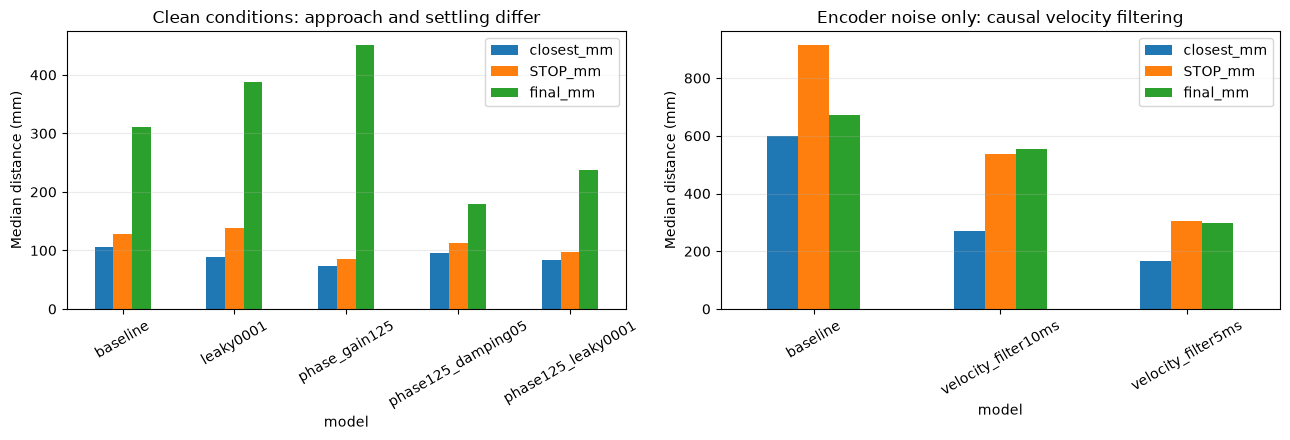

In [2]:
selected=table[(table.batch.isin(['egl_batch01','egl_arch01','egl_batch02'])) & (table.model.isin(['baseline','leaky0001','phase_gain125','phase125_leaky0001','phase125_damping05']))].drop_duplicates('model')
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
selected.set_index('model')[['closest_mm','STOP_mm','final_mm']].plot.bar(ax=axes[0])
axes[0].set_ylabel('Median distance (mm)');axes[0].set_title('Clean conditions: approach and settling differ')
noise=table[table.batch.eq('egl_filter_noise')].set_index('model')
noise[['closest_mm','STOP_mm','final_mm']].plot.bar(ax=axes[1])
axes[1].set_title('Encoder noise only: causal velocity filtering');axes[1].set_ylabel('Median distance (mm)')
for ax in axes: ax.tick_params(axis='x',rotation=30);ax.grid(axis='y',alpha=.25)
plt.tight_layout();plt.savefig(ROOT/'research_comparison.png',dpi=150);plt.show()


## What the tests establish

Increasing the arm's PARK-input weights improves the approach on the development targets, but does not solve stopping or settling. Multiplying this pathway by 1.25 reduced median closest distance from 106 to 74 mm and STOP distance from 128 to 86 mm on six cases, while final distance worsened from 311 to 452 mm. On twenty additional validation targets it reduced median closest distance from 86 to 52 mm, but still achieved zero 10 mm successes. This is a useful mechanism, not an accepted final controller.

Small leaky activations alter behaviour but have no consistent accuracy advantage. None of the 44 second-layer neurons inactive on sampled expert data activated before STOP in the inspected failed student trace. That observation does not support pruning or reviving them as the primary repair. Reducing joint 7 sensitivity and adding fixed viscous feedback also failed their checks.

Improving the calibrated RGB-D target estimator reduced visible-frame measurement error from roughly 9–21 mm to about 2 mm on six traces. The unchanged controller did not improve consistently with those corrected inputs. Better measurement requires a matched training distribution; pixel calibration alone is not a control solution.

A 5 ms causal filter on encoder-derived joint speeds substantially reduced errors under encoder noise, while worsening clean performance when added without retraining. The filter therefore remains an experimental processing change. It is not silently installed in the baseline.

A learned history residual slightly improved offline torque loss but worsened simulation outcomes. Its comparison, losses and exact runtime records are in `history_branch`. Offline loss reduction is not sufficient evidence of control improvement.

None of these parameter-only candidates achieved the 10 mm PARK-and-STOP success criterion on the development cases. Later architecture experiments are reported separately below.

## What inspecting the original weights revealed

The audit evaluated 26,867 sampled rows from all 100 training demonstrations. In the arm's second 128-unit hidden layer, 44 ReLU units never activated on those sampled rows; one unit in the independent STOP network was also inactive. This does not establish that they are permanently dead or that removing them would improve control. The first arm hidden layer had no always-inactive units in this sample.

Weights and biases are fully accessible numerical arrays, but an individual value rarely has an isolated behavioural meaning. The plots measure how often each unit participates, rather than assigning a label such as “parking neuron”. Changes to an activation function also change the fitted function and must be evaluated as new candidates. The activation and gain edits preserved in the early development tables did not establish reliable reaching, which motivated the later structural experiments.

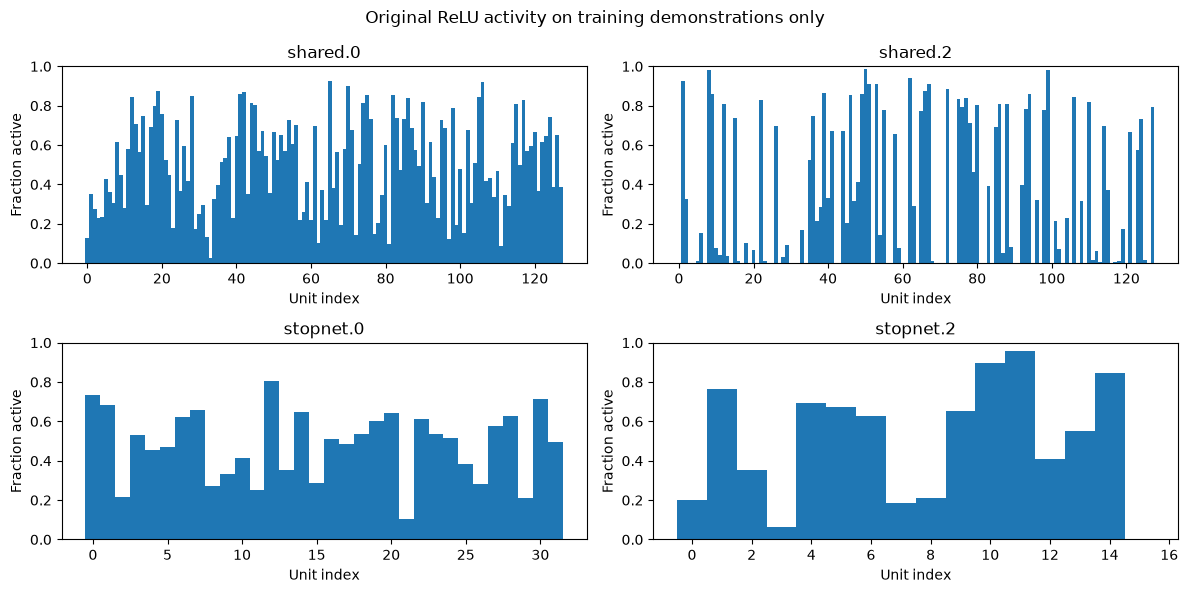

,layer,width,inactive_on_sample,median_fraction_active
0,shared.0,128,0,0.523
1,shared.2,128,44,0.096
2,stopnet.0,32,0,0.514
3,stopnet.2,16,1,0.590


In [3]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT=Path.cwd()
activation=json.loads((ROOT/'activation_audit.json').read_text())
fig,axes=plt.subplots(2,2,figsize=(12,6))
rows=[]
for ax,(name,layer) in zip(axes.flat,activation['layers'].items()):
    fraction=np.asarray(layer['positive_fraction'])
    ax.bar(np.arange(len(fraction)),fraction,width=1)
    ax.set(title=name,xlabel='Unit index',ylabel='Fraction active',ylim=(0,1))
    rows.append(dict(layer=name,width=layer['width'],inactive_on_sample=len(layer['inactive_on_all_sampled_rows']),
        median_fraction_active=float(np.median(fraction))))
fig.suptitle('Original ReLU activity on training demonstrations only')
fig.tight_layout();fig.savefig(ROOT/'original_activation_activity.png',dpi=150);plt.show()
display(pd.DataFrame(rows).round(3))


## Matched filter fine-tuning, plan recorded before execution

Hypothesis: causal speed filtering reduces differentiation noise, but the unchanged model misinterprets the lag. Compare the same warm-start fine-tune with raw speeds and with a 5 ms exponential filter. The filter runs at 1 kHz, resets at episode reset and uses only current/past encoder measurements. Angles, camera inputs, driving and physical conditions are unchanged.

Both candidates retain the arm 18→128→128 torque/auxiliary outputs and the independent STOP 18→32→16→1 network. Optimise them independently on the original 100 clean training demonstrations, with equal mean loss per run, Adam learning rate 0.0001 and 300 updates. Use the original training-derived scales. Choose each component's earliest minimum validation total loss across the 100 validation demonstrations. No recovery data, DART or DAgger is used. Store all histories and export parity checks.

Compare both candidates on the same six complete validation episodes under clean physics and encoder noise only. A useful result must improve noise robustness without an unacceptable loss of clean accuracy or completion. The full disturbance stack is a separate follow-up; this check does not claim to cover it.

## Learned position-based STOP, plan recorded before training

Test whether a structured neural distance estimator transfers better than the existing direct-distance MLP. A separate 14→64 tanh→64 tanh→3 network receives sine and cosine of the seven measured encoder angles and predicts the gripper position in the robot base frame. STOP distance is the norm of that predicted position minus the camera/tracker target estimate. No robot link lengths, URDF, simulator state or expert reference enters this estimator at runtime.

Supervision consists of the original training demonstrations' pre-step gripper positions, transformed into the base frame using recorded pose only when constructing labels. Validation labels use the same transform. Keep every tenth 1 kHz sample, retain equal episode weights, use seed 7, Adam 0.003 and at most 1,000 updates. Choose the earliest minimum validation position MSE. Save all losses and verify exported inference.

First measure position and STOP-distance errors on existing exact-input student traces, without changing their trajectories. If useful, test the same six complete validation episodes with frozen driving and arm weights. Include the original STOP and auxiliary training output unchanged in the source checkpoint, but explicitly override the actionable STOP estimate only in this isolated experimental runtime. This is a new engineered architecture, not a pure weight edit or a claim of new test performance.

## Trigonometric position model, plan before fitting

Fit a linear encoder-to-gripper position model on tensor-product features [1, sin(q), cos(q)]. Rotational geometry motivates these features, but every position coefficient comes from the original demonstration labels: no URDF, link lengths or runtime simulator truth. Compare all seven joint angles with a six-angle feature ablation; do not assume the last joint is irrelevant. There are 2,187 or 729 features, respectively, and three learned coordinates.

Use the same 100 training and 100 validation episodes at 10 ms spacing and equal episode weights. Solve ridge regression in FP64 for ridge values 1e-12, 1e-10, 1e-8, 1e-6 and 1e-4; choose minimum weighted validation coordinate MSE. Report post-PARK errors separately so the long, nearly stationary pre-PARK interval cannot conceal poor reaching estimates. Test the chosen model on existing student traces before altering runtime STOP. This tests an interpretable feature basis and closed-form fitting, not privileged runtime state or an exact analytical simulator.

## Interpretable learned torque decoder, identification plan

Fit an explicit torque map from original demonstrations: a learned trigonometric position term plus learned per-joint reference-error and velocity-error coefficients. This is a separately labelled engineered controller architecture, not the baseline or a claim of pure behaviour cloning. Every coefficient is estimated from training data. There is no runtime mass matrix, URDF or analytical gravity term.

The teacher reference angle and desired velocity may enter coefficient fitting as training signals. They must never enter runtime control; any evaluated model must generate its own reference and desired velocity from its sensors. Use counted angles and counted speed in fitting, preserve the pre-step command alignment, and record the exact source hashes.

Because clipped torque labels conceal the underlying linear value, fit only rows where each output is inside 29.5 Nm, with equal weights across each run's eligible rows. This is an identification loss mask, not deleted data or a revised expert record. Select ridge strength from 1e-12, 1e-10, 1e-8 and 1e-6 using validation error on ALL rows after applying the actual +/-30 Nm output clipping. Retain and report all masks and candidate gains. Negative fitted restoring/damping gains invalidate automatic promotion. First audit identified gains and offline fit; no runtime deployment is implied by fitting.

## Geometry fit conditioning check, plan before fitting

The ridge fit predicts positions accurately on demonstration states, but larger errors remain during large student departures. Test whether loss of numerical precision from forming a Gram matrix is responsible. Fit the six-angle, 729-feature version directly with weighted FP64 SVD, using counted angles and exactly the same labels, stride and episode weights. Compare singular-value cutoffs 1e-8, 1e-10 and 1e-12 and select minimum validation position MSE. Report rank, coefficient norm and post-PARK errors; then inspect the same student traces. Do not treat training residual alone as evidence of extrapolation accuracy.

## Sparse marker sensing check

Case 80 had only three visible red pixels at STOP, so the calibrated sphere estimator used its original centroid fallback. Compare a minimum of three, four and six surface pixels using the same calibrated rays, known marker radius, optimisation steps and displacement guard. Re-render every second saved frame from the six original-camera learned-controller validation episodes. Simulator truth scores estimates but never enters fitting. Report 3–5 pixel cases separately, with tail errors, before choosing whether to change the arm sensor runtime. Driving sensing remains unchanged.

## Learned geometry and structured torque control

This is a separate R&D controller, not an improved score for the original behaviour-cloning architecture. The driving network is frozen. The reaching controller learns a position map and torque coefficients from the original 100 training demonstrations, then uses a designed reference integrator and damped Jacobian servo. It has no runtime URDF, analytical mass matrix, true base pose, true target position or expert reference. All seven joint torques run from reset, including before PARK.

The position model is linear in products of `[1, sin(q), cos(q)]`, fitted to recorded gripper position expressed in the base frame. Simulator positions and orientation are training labels, not deployed inputs. The torque decoder learns a position-dependent feedforward term and diagonal reference-error and velocity-error coefficients. Recorded expert references supervise that identification offline. At runtime the controller integrates its own reference; it never receives the expert's reference. The learned feedforward term behaves like gravity compensation, but is fitted from demonstrations rather than calculated from a dynamics model. This structural prior and the hand-written servo must be disclosed in any comparison with pure imitation learning.

The torque fit uses unsaturated training commands, where the underlying linear relationship is identifiable. Validation includes all rows with the same output clipping. This is a loss mask for coefficient identification, not a modification of the stored expert recordings. Geometry and torque regularisation are selected on validation demonstrations; the reserved test files remain unopened in this R&D.

The original arm/STOP networks are retained as frozen baseline artifacts. The new controller replaces their runtime torque and STOP calculation; it does not receive an additional learned STOP output. STOP uses estimated camera-to-gripper distance. A valid success still requires PARK, STOP and the simulator-scored distance at that STOP step to be at most 10 mm. Getting close later is not counted as success.

In [4]:
from pathlib import Path
import json, numpy as np, pandas as pd
ROOT=Path.cwd()
BR=ROOT/'learned_geometry_branch'
specs=[
('Original baseline',ROOT/'egl_batch01/baseline',6),
('Learned geometry, original camera',BR/'original_validation',6),
('Calibrated arm camera',BR/'calibrated_validation',6),
('5 ms velocity filter',BR/'filtered6_original_validation',6),
('Observed posture envelope',BR/'envelope_original_validation',6),
('Envelope + calibrated camera',BR/'envelope_calibrated_validation',6),
('Identified lower reference bound',BR/'identified_original_validation',6),
('Identified bound + calibrated camera',BR/'identified_calibrated_validation',6),
('Identified bound + confident camera',BR/'gated_identified_validation',6),
('Envelope + confident camera',BR/'gated_envelope_validation',6),
('Hybrid lower bounds',BR/'hybrid_posture_gate_v1/validation6',6),
('Hybrid + gain 1.5',BR/'hybrid_gain15_v1/validation6',6),
('Gain 1.5 + STOP 5 mm',BR/'hybrid_gain15_stop5_v1/validation6',6),
('Identified bound, wider validation',BR/'frozen_identified_gate_v1/broader_validation20',20),
('Hybrid, wider validation',BR/'hybrid_posture_gate_v1/broader_validation20',20),
('Hybrid gain 1.5, wider validation',BR/'hybrid_gain15_v1/broader_validation20',20),
('Gain 1.5 + STOP 5 mm, wider validation',BR/'hybrid_gain15_stop5_v1/broader_validation20',20),
('Frozen candidate, remaining validation',BR/'hybrid_gain15_stop5_v1/remaining_validation74',74),
]
rows=[]
for label,folder,expected in specs:
    rr=[json.loads(p.read_text()) for p in sorted(folder.glob('run_*.json'))]
    if not rr: continue
    def med(key):
        vals=[r[key] for r in rr if r.get(key) is not None]
        return float(np.median(vals)) if vals else np.nan
    stops=[r for r in rr if r.get('at_network_stop_mm') is not None]
    rows.append(dict(model=label,complete=len(rr)==expected,N=len(rr),expected=expected,
                     PARK=sum(bool(r.get('parked')) for r in rr),STOP=len(stops),
                     success_10mm=sum(bool(r.get('success')) for r in rr),
                     closest_mm=med('min_mm'),STOP_mm=med('at_network_stop_mm'),final_mm=med('end_mm'),
                     execution_failures=sum(r.get('status')=='execution_failure' for r in rr)))
geometry_results=pd.DataFrame(rows)
display(geometry_results.round(2))
geometry_results.to_csv(ROOT/'geometry_research_results.csv',index=False)


,model,complete,N,expected,PARK,STOP,success_10mm,closest_mm,STOP_mm,final_mm,execution_failures
0,Original baseline,True,6,6,6,6,0,105.75,128.40,310.60,0
1,"Learned geometry, original camera",True,6,6,6,5,0,32.06,37.79,38.21,0
2,Calibrated arm camera,True,6,6,6,5,1,33.08,36.14,38.01,0
3,5 ms velocity filter,True,6,6,6,5,0,31.67,34.48,35.11,0
4,Observed posture envelope,True,6,6,6,5,1,29.15,30.02,30.63,0
5,Envelope + calibrated camera,True,6,6,6,3,2,22.40,9.54,23.70,0
6,Identified lower reference bound,True,6,6,6,5,0,32.95,32.99,35.94,0
7,Identified bound + calibrated camera,True,6,6,6,4,1,33.02,35.38,36.52,0
8,Identified bound + confident camera,True,6,6,6,5,5,6.11,8.65,6.11,0
9,Envelope + confident camera,True,6,6,6,5,5,6.18,8.76,6.17,0


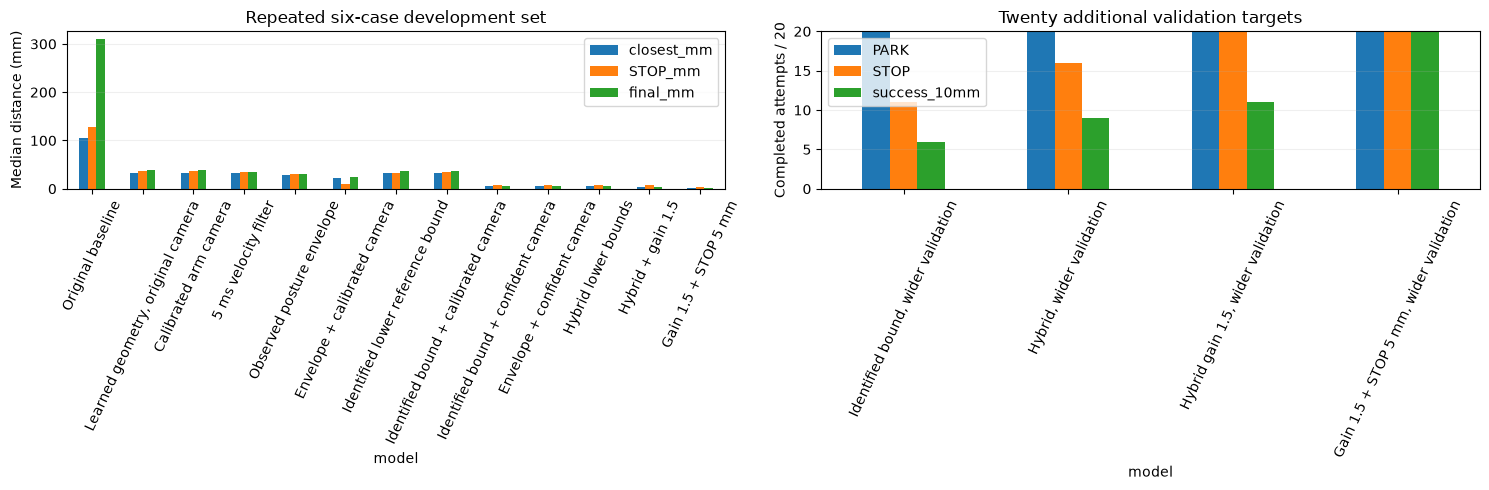

In [5]:
import matplotlib.pyplot as plt
complete=geometry_results[geometry_results.complete]
six=complete[complete.expected.eq(6)]
wide=complete[complete.expected.eq(20)]
fig,axes=plt.subplots(1,2,figsize=(15,5))
six.set_index('model')[['closest_mm','STOP_mm','final_mm']].plot.bar(ax=axes[0])
axes[0].set_ylabel('Median distance (mm)');axes[0].set_title('Repeated six-case development set')
if len(wide):
    wide.set_index('model')[['PARK','STOP','success_10mm']].plot.bar(ax=axes[1])
    axes[1].set_ylim(0,20);axes[1].set_title('Twenty additional validation targets')
    axes[1].set_ylabel('Completed attempts / 20')
for ax in axes:
    ax.tick_params(axis='x',rotation=65);ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.savefig(ROOT/'geometry_research_comparison.png',dpi=150);plt.show()


## What changed the result

Improving the RGB-D estimate alone was insufficient. With fewer than six red pixels, the original estimator fell back to a biased centroid/range estimate and could overwrite a previously accurate track. The successful camera change rejects those low-confidence arm observations and lets the existing encoder tracker predict until another accepted observation arrives. Driving keeps its original camera processing. Successful development STOPs were checked for fresh accepted images; stale tracking is not assumed to be harmless.

The first confident-camera candidate passed five of six development cases, but only six of twenty additional validation cases. Its median final distance was 8.6 mm; that did not imply a high STOP success rate. Nine timed out and five stopped just outside 10 mm. Every one remains in the denominator. The hybrid lower-bound controller passed all six development cases, but nine of twenty additional cases. These comparisons show why the repeated six targets cannot establish generalisation.

The hybrid controller has two explicit posture constraints: joint 6's lower reference plateau is inferred from repeated expert reference behaviour in training; joint 2's lower value is the minimum observed training posture. Neither is presented as a measured hardware limit. Removing the unsupported upper envelope avoids blocking valid reaching motions. The constraints are identical across targets, with no target-specific controller selection.

Increasing Cartesian gain from 0.8 to 1.5 is a separate experiment with the same speed cap, camera processing, torque coefficients and episode time budget. It removed the four remaining timeouts in the twenty-case check, but only eleven STOPs met the true 10 mm criterion. A subsequent separate change lowered the estimated-distance STOP trigger to 5 mm. Rerunning all twenty cases gave twenty valid successes, median true STOP distance 5.14 mm and median final distance 3.90 mm. The scoring criterion and deadlines were unchanged. These are actual reruns, not retrospective relabelling.

These are validation development results. No official iteration number or MLflow test result is assigned here. Repeated selection on these cases means an eventual frozen evaluation needs the remaining validation targets and reserved tests.

,0
status,"complete frozen validation100, not test"
attempted,100
PARK,100
STOP,95
success_10mm,95
execution_failures,0
median_closest_mm,3.697557
median_final_mm_all_attempts,3.763995
median_STOP_mm_conditional,5.408004
p95_STOP_mm_conditional,6.242488


,dot,status,park_s,limit_s,min_mm,at_network_stop_mm,end_mm
0,257,no_stop_timeout,10.433,12.000,85.078052,None,84.963612
1,359,no_stop_timeout,9.500,12.000,6.863364,None,6.856775
2,421,no_stop_timeout,9.267,12.000,3.666650,None,3.640202
3,438,no_stop_timeout,10.733,13.399,7.590358,None,7.581521
4,749,no_stop_timeout,10.833,12.354,7.343517,None,7.333328


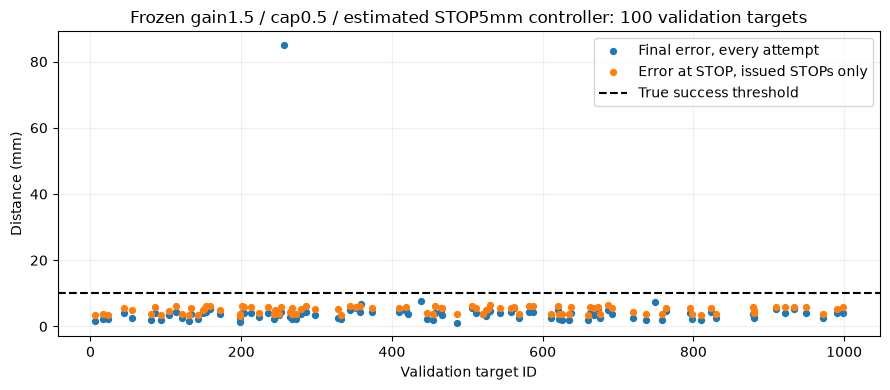

In [6]:
aggregate=json.loads((BR/'hybrid_gain15_stop5_v1/aggregate_validation100.json').read_text())
display(pd.DataFrame([{k:v for k,v in aggregate.items() if k not in ['rows','failures']}]).T)
display(pd.DataFrame(aggregate['failures']))
complete_rows=pd.DataFrame(aggregate['rows'])
fig,ax=plt.subplots(figsize=(9,4))
ax.scatter(complete_rows['dot'],complete_rows.end_mm,label='Final error, every attempt',s=18)
ax.scatter(complete_rows['dot'],complete_rows.at_network_stop_mm,label='Error at STOP, issued STOPs only',s=18)
ax.axhline(10,color='black',linestyle='--',label='True success threshold')
ax.set(xlabel='Validation target ID',ylabel='Distance (mm)',title='Frozen gain1.5 / cap0.5 / estimated STOP5mm controller: 100 validation targets')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.savefig(ROOT/'geometry_validation100.png',dpi=150);plt.show()


The frozen candidate completed all 100 validation targets with 100 PARKs and 95 STOPs. All 95 issued STOPs met the true 10 mm criterion; the largest STOP error was 6.37 mm. Median final error over all 100 attempts was 3.76 mm. Five timeouts remain failures, including four whose final position was already within 10 mm. All three batches used the same source and model hashes. The initial six and subsequent twenty informed development; the remaining 74 were run without changing the candidate.

A subsequent candidate increases Cartesian gain to 2.5 and the joint-speed cap to 1.0 rad/s, retaining the same 5 mm estimated STOP trigger and episode deadlines. Its targeted eleven-case check passed ten cases; target 257 still timed out. Its separate 100-target validation completed with 99 successful STOPs, median STOP error 5.06 mm and median final error 2.78 mm. Target 257 still timed out at 35.38 mm. A later gain6 targeted probe passed all eleven selected cases but drifted to 24.74 mm after STOP on target45; canonical success alone therefore does not establish stable settling. No rows from that later candidate replace failures in the frozen 95/100 result.

In [7]:
torque_fit=json.loads((ROOT/'identified_torque_training/summary.json').read_text())
display(pd.DataFrame([dict(joint=r['selected']['joint'],Kp=r['selected']['Kp'],Kd=r['selected']['Kd'],
                          validation_MAE_Nm=r['selected']['errors']['val']['MAE_Nm'],
                          fit_rows=r['selected']['eligible_fit_rows'],all_rows=r['selected']['training_rows'])
                     for r in torque_fit['fit']]).round(5))
audit=json.loads((ROOT/'svd_geometry_shadow_audit.json').read_text())
display(pd.DataFrame(audit['timing']).round(3))
display(pd.DataFrame(audit['rows']).groupby(['group','model']).agg(
    cases=('dot','count'),median_case_error_mm=('median_mm','median'),worst_case_p95_mm=('p95_mm','max')))


,joint,Kp,Kd,validation_MAE_Nm,fit_rows,all_rows
0,1,99.97108,29.99299,0.01767,88545,88547
1,2,100.11168,30.01477,0.01740,87873,88547
2,3,99.95416,29.99821,0.01693,88183,88547
3,4,100.14981,30.01040,0.01754,88396,88547
4,5,100.04472,29.99410,0.02485,88543,88547
5,6,99.94970,29.97890,0.00812,88313,88547
6,7,100.10723,29.99446,0.02269,88546,88547


,model,median_us,p95_us,samples,max_jacobian_finite_difference_error
0,seven_angle_ridge,705.173,949.542,184,0.0
1,six_angle_svd,491.550,607.041,184,0.0


cases  \
group                                              model                      
egl_batch01/baseline                               seven_angle_ridge      6   
                                                   six_angle_svd          6   
learned_geometry_branch/frozen_identified_gate_... seven_angle_ridge     20   
                                                   six_angle_svd         20   
learned_geometry_branch/gated_identified_valida... seven_angle_ridge      6   
                                                   six_angle_svd          6   

                                                                      median_case_error_mm  \
group                                              model                                     
egl_batch01/baseline                               seven_angle_ridge              0.051349   
                                                   six_angle_svd                  0.017688   
learned_geometry_branch/frozen_identified_gate_... seven_angle_ridge              0.018346   
                                                   six_angle_svd                  0.005040   
learned_geometry_branch/gated_identified_valida... seven_angle_ridge              0.054260   
                                                   six_angle_svd                  0.010614   

                                                                      worst_case_p95_mm  
group                                              model                                 
egl_batch01/baseline                               seven_angle_ridge          39.246602  
                                                   six_angle_svd               6.715561  
learned_geometry_branch/frozen_identified_gate_... seven_angle_ridge           0.468918  
                                                   six_angle_svd               0.093840  
learned_geometry_branch/gated_identified_valida... seven_angle_ridge           0.126510  
                                                   six_angle_svd               0.075938

## Geometry efficiency check

A six-angle direct-SVD fit uses 729 features instead of 2,187. On the twenty recorded controller trajectories its median case position error was 0.005 mm, with a worst-case 95th-percentile error of 0.094 mm. The seven-angle fit gave 0.018 mm and 0.469 mm respectively. Both errors are much smaller than the camera error on these trajectories.

In a timing check while simulations were running, position plus Jacobian evaluation fell from roughly 705 to 492 microseconds median. This is a measured component speedup, not a claim about whole-simulation throughput or guaranteed 1 kHz hardware control. The SVD replacement remains a separate candidate until live parity and validation are complete.

## Feedback, delay and settling

The activation and weight-edit experiments did not establish reliable reaching. The strongest candidate changes the architecture: a learned position map, an identified torque decoder and explicit feedback. No runtime simulator target, base pose or expert reference is supplied to it. These are engineered-control R&D results, not scores for the original behaviour-cloning network.

The clean candidate's 95/100 result rose to 99/100 after increasing Cartesian gain and the speed cap. Raising the gain again solved the remaining late-PARK case in a targeted check, but introduced post-STOP movement on another case. The next intervention adds Cartesian velocity-error damping while retaining the original joint feedback. Three targeted cases passed with exact 1 kHz post-STOP peaks below 5 mm. The unchanged candidate is then evaluated across all 100 validation targets.

The diagnostic recorder reads true distance only for logging and scoring. Its parity check reproduced every original result field and replay frame exactly on target45. The new stability statistic is the largest true distance during the recorded 0.5 seconds after STOP; it does not replace the canonical 10 mm-at-STOP score. None of these checks establishes physical safety.

In [8]:
import json, numpy as np, pandas as pd
from pathlib import Path
ROOT=Path.cwd()
specs=[('Gain2.5 cap1', 'clean_gain25_cap1_validation100',100),
       ('Gain6 cap1 targeted', 'clean_gain6_cap1_probe',11),
       ('Gain6 + Cartesian damping20 targeted','clean_gain6_cap1_damping20_probe',11),
       ('Gain6 + Cartesian damping40 targeted','clean_damping40_targeted3',3),
       ('Frozen gain6 + damping40','clean_gain6_damping40_validation100',100),
       ('Reference recovery, targeted3','clean_reference_recovery_targeted3',3),
       ('Reference recovery, expanded12','clean_reference_recovery_expanded12',12),
       ('Frozen reference recovery','clean_reference_recovery_validation100',100)]
rows=[]
for label,folder,expected in specs:
    p=ROOT/folder/'summary.json'
    if not p.exists():continue
    r=json.loads(p.read_text())
    def median(key):
        v=[x[key] for x in r if x.get(key) is not None]
        return np.median(v) if v else np.nan
    peaks=[x['post_stop_peak_mm'] for x in r if x.get('post_stop_peak_mm') is not None]
    rows.append(dict(candidate=label,attempts=len(r),expected=expected,complete=(ROOT/folder/'completion.json').exists(),
        success=sum(bool(x.get('success')) for x in r),STOP_mm=median('at_network_stop_mm'),final_mm=median('end_mm'),
        exact_peak_mm=max(peaks) if peaks else np.nan,
        settle_success=sum(bool(x.get('within_10mm_through_post_stop')) for x in r) if peaks else np.nan))
display(pd.DataFrame(rows).round(3))


,candidate,attempts,expected,complete,success,STOP_mm,final_mm,exact_peak_mm,settle_success
0,Gain2.5 cap1,100,100,True,99,5.061,2.776,NaN,NaN
1,Gain6 cap1 targeted,11,11,True,11,4.049,3.109,NaN,NaN
2,Gain6 + Cartesian damping20 targeted,11,11,True,11,3.854,2.590,NaN,NaN
3,Gain6 + Cartesian damping40 targeted,3,3,True,3,4.411,2.665,4.893,3.0
4,Frozen gain6 + damping40,100,100,True,98,4.430,2.481,48.344,87.0
5,"Reference recovery, targeted3",3,3,True,3,4.940,2.087,5.117,3.0
6,"Reference recovery, expanded12",12,12,True,12,4.718,2.826,6.321,12.0
7,Frozen reference recovery,100,100,True,100,5.123,2.856,6.819,100.0


## Existing disturbance stack

The stack retains encoder noise, motor damping, elasticity, additional inertia, 3 ms measurement delay and random starting poses. It does not include occlusion or bursty recording loss. No DART or DAgger data or checkpoints are used.

On the diagnosed random-start target45, delay alone reproduced a roughly 35 Hz oscillation; removing delay from the full stack removed that oscillation. This is a controlled result for that case, not a universal claim about delay. The correction keeps the delay enabled. Joint-specific damping reductions suppressed the fast mode, but some variants still moved away after STOP. Adding Cartesian damping20 then gave six successful STOPs with exact post-STOP peaks below 5.7 mm and no post-STOP command clipping.

The frozen broader20 validation gave 18 successful STOPs; every successful attempt stayed within 6.16 mm during its recorded post-STOP interval. Two cases timed out and remain failures. Their true final distances were 11.00 and 8.42 mm. The next controlled change increases the approach gain alone, keeping the speed cap and physical disturbances unchanged.

Two alternative hypotheses failed: a causal extrapolated velocity estimate and a projected joint-feedback controller both produced zero successes on the six development targets. These failures remain in their saved directories. Neither is installed in the successful candidate.

Motor logging distinguishes requested torque from final sent torque. The native field called `applied_arm_torque` records the clipped request; motor effects are added afterward in `sent_arm_torque`. Therefore requested-command clipping is not a guarantee that physical torque stayed inside that request limit.

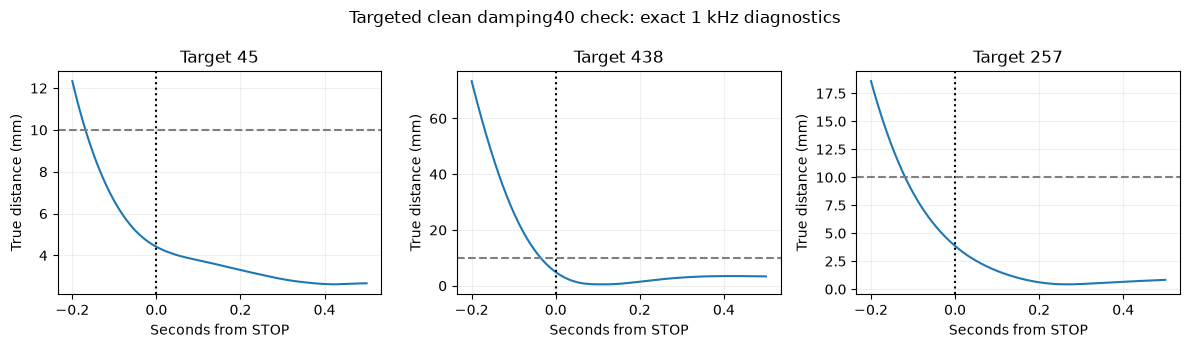

In [9]:
import matplotlib.pyplot as plt
folder=ROOT/'clean_damping40_targeted3'
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,dot in zip(axes,[45,438,257]):
    row=json.loads((folder/f'run_{dot}.json').read_text())
    with np.load(folder/f'truth_{dot}.npz') as z:
        t=z['time_s']-row['stop_s'];d=1000*z['distance_m'];mask=t>=-.2
        ax.plot(t[mask],d[mask]);ax.axvline(0,color='black',ls=':');ax.axhline(10,color='grey',ls='--')
    ax.set(title=f'Target {dot}',xlabel='Seconds from STOP',ylabel='True distance (mm)')
    ax.grid(alpha=.2)
fig.suptitle('Targeted clean damping40 check: exact 1 kHz diagnostics')
fig.tight_layout();fig.savefig(ROOT/'clean_damping40_settling.png',dpi=150);plt.show()


## Reference validity from reset

The full gain6/damping40 evaluation completed with 98/100 valid STOPs, but only 87/100 stayed within 10 mm for the whole post-STOP interval. The canonical metric alone concealed those excursions.

On target159, joint6's own reference remained below the existing training-derived lower bound. A sudden measured velocity increase occurred while the preceding requested torque was small. Inspection of the simulator's joint limits supports a limit-response explanation; those hardware limits were used only for diagnosis and were not added as policy inputs or substituted for the learned bounds. The active-set solver blocked outward task velocity but did not bring an already-invalid reference back into its permitted range.

The next candidate makes one change: recover the controller's own reference toward its existing learned lower bounds at at most 0.1 rad/s, starting at reset. There is no instantaneous projection, no expert reference during deployment and no changed time budget. This is an explicit engineered posture constraint, not a neural activation change. The three targeted cases and twelve further diagnostic cases all reached and stayed within 10 mm. A separate unchanged 100-target validation follows; its live status appears in the table above.

The correction also changed target273's camera visibility: the previous controller used a track last observed 3.934 seconds earlier and stopped 34.01 mm away; the new trajectory had a fresh 14-pixel observation and stopped 5.12 mm away. This is an indirect benefit of the changed posture, not proof that stale tracking has been solved in general. Camera processing and driving weights remained fixed.

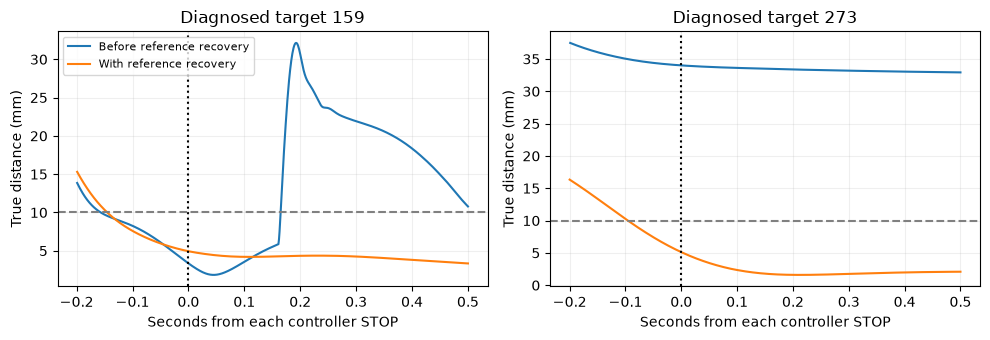

In [10]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for ax,dot in zip(axes,[159,273]):
    for folder,label in [('clean_gain6_damping40_validation100','Before reference recovery'),
                         ('clean_reference_recovery_targeted3','With reference recovery')]:
        rr=ROOT/folder;row=json.loads((rr/f'run_{dot}.json').read_text())
        with np.load(rr/f'truth_{dot}.npz') as z:
            t=z['time_s']-row['stop_s'];mask=t>=-.2
            ax.plot(t[mask],1000*z['distance_m'][mask],label=label)
    ax.axvline(0,color='black',ls=':');ax.axhline(10,color='grey',ls='--')
    ax.set(title=f'Diagnosed target {dot}',xlabel='Seconds from each controller STOP',ylabel='True distance (mm)')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8);fig.tight_layout();fig.savefig(ROOT/'reference_recovery_diagnostics.png',dpi=150);plt.show()


## Frozen clean evaluation

The reference-recovery candidate completed 100 validation episodes with 100 canonical successes, 100 settling successes and no internal-motion audit flags. Its source and model hashes were frozen before the reserved test records were copied into this research workspace. The recorded prediction was at least 95 successes out of 100. No test outcomes select a new setting or model. These golden test targets have historical project exposure; they are reserved within this research exercise, not an independently collected unseen benchmark.

The architecture is learned geometry and identified torque with explicit feedback, not the original MLP with edited weights. Simulator poses supply offline geometry labels and evaluation diagnostics only. Expert internal references are used during torque identification only. The runtime generates its own reference. The identified feedforward torque provides gravity-like compensation, and a geometric threshold controls STOP. This is an engineered model-based extension with learned components.

The table includes only completed evaluations. Canonical success requires PARK, STOP and no more than 10 mm true gripper distance at STOP. Settling additionally requires the exact 1 kHz distance to remain within 10 mm for the next 0.5 seconds. A missing STOP fails both. Medians on stopped episodes must be read alongside the full attempt count.

In [11]:
import json, numpy as np, pandas as pd
from pathlib import Path
ROOT=Path.cwd()
completed=[]
for split,folder in [('validation','clean_reference_recovery_validation100'),('test','clean_reference_recovery_test100')]:
    d=ROOT/folder
    if not (d/'completion.json').exists():continue
    rr=json.loads((d/'summary.json').read_text())
    audit=json.loads((d/'motion_audit.json').read_text()) if (d/'motion_audit.json').exists() else None
    def q(key,quantile=.5):
        vals=[x[key] for x in rr if x.get(key) is not None]
        return float(np.quantile(vals,quantile)) if vals else np.nan
    completed.append(dict(split=split,attempts=len(rr),PARK=sum(x.get('park_s') is not None for x in rr),STOP=sum(x.get('stop_s') is not None for x in rr),
        canonical_success=sum(bool(x.get('success')) for x in rr),settled_success=sum(bool(x.get('within_10mm_through_post_stop')) for x in rr),
        median_STOP_mm=q('at_network_stop_mm'),p95_STOP_mm=q('at_network_stop_mm',.95),median_final_mm=q('end_mm'),
        max_postSTOP_mm=q('post_stop_peak_mm',1),internal_flags=len(audit['flagged']) if audit else 'pending'))
display(pd.DataFrame(completed).round(3))


,split,attempts,PARK,STOP,canonical_success,settled_success,median_STOP_mm,p95_STOP_mm,median_final_mm,max_postSTOP_mm,internal_flags
0,validation,100,100,100,100,100,5.123,6.434,2.856,6.819,0
1,test,100,100,100,100,100,5.279,6.482,2.897,8.988,1


## Fitting evidence

These components use linear coefficient fitting, so there are no neural training epochs to plot for them. Geometry coefficients are fitted on the training episodes; ridge strength is selected using validation coordinate error. Torque coefficients and gains are identified from unsaturated training rows, weighted equally per eligible episode, and scored on all validation rows after command clipping. The plots below show those actual candidate losses. They are offline fit measurements, not robot success rates.

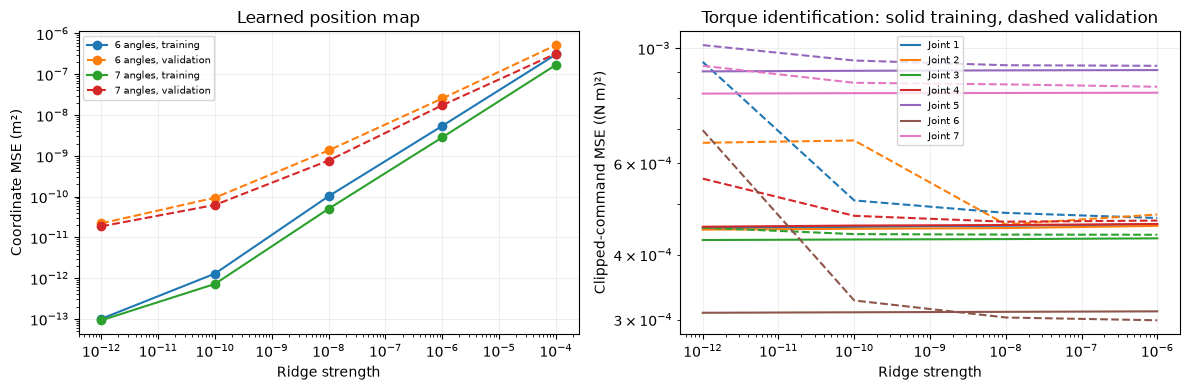

In [12]:
import matplotlib.pyplot as plt
position=json.loads((ROOT/'trig_position_training/summary.json').read_text())
torque=json.loads((ROOT/'identified_torque_training/summary.json').read_text())
fig,axes=plt.subplots(1,2,figsize=(12,4))
for n in [6,7]:
    cc=sorted([x for x in position['candidates'] if len(x['axes'])==n],key=lambda x:x['ridge'])
    for split,style in [('training','-'),('validation','--')]:
        axes[0].loglog([x['ridge'] for x in cc],[x[split+'_mse'] for x in cc],style,marker='o',label=f'{n} angles, {split}')
axes[0].set(xlabel='Ridge strength',ylabel='Coordinate MSE (m²)',title='Learned position map')
for i,entry in enumerate(torque['fit']):
    cc=sorted(entry['candidates'],key=lambda x:x['ridge'])
    line=axes[1].loglog([x['ridge'] for x in cc],[x['errors']['train']['mse'] for x in cc],'-',label=f'Joint {i+1}')[0]
    axes[1].loglog([x['ridge'] for x in cc],[x['errors']['val']['mse'] for x in cc],'--',color=line.get_color())
axes[1].set(xlabel='Ridge strength',ylabel='Clipped-command MSE ((N m)²)',title='Torque identification: solid training, dashed validation')
for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(ROOT/'identified_model_fit.png',dpi=150);plt.show()


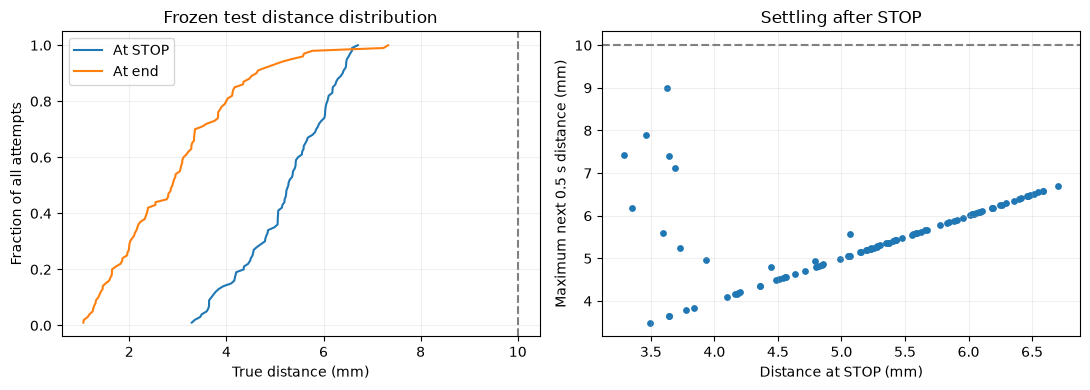

In [13]:
test=ROOT/'clean_reference_recovery_test100'
if (test/'completion.json').exists():
    rr=json.loads((test/'summary.json').read_text())
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for key,label in [('at_network_stop_mm','At STOP'),('end_mm','At end')]:
        vv=np.sort([x[key] for x in rr if x.get(key) is not None]);axes[0].plot(vv,np.arange(1,len(vv)+1)/len(rr),label=label)
    axes[0].set(xlabel='True distance (mm)',ylabel='Fraction of all attempts',title='Frozen test distance distribution');axes[0].axvline(10,color='grey',ls='--');axes[0].legend()
    rows=sorted(rr,key=lambda x:x['dot']);axes[1].scatter([x['at_network_stop_mm'] for x in rows if x.get('stop_s') is not None],[x['post_stop_peak_mm'] for x in rows if x.get('stop_s') is not None],s=15)
    axes[1].set(xlabel='Distance at STOP (mm)',ylabel='Maximum next 0.5 s distance (mm)',title='Settling after STOP');axes[1].axhline(10,color='grey',ls='--')
    for ax in axes:ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(ROOT/'frozen_test_distances.png',dpi=150);plt.show()
else:
    print('Frozen test evaluation is still running. No partial score is used to change the candidate.')


## Reading the frozen clean test

The frozen model achieved 100/100 canonical successes and 100/100 settling successes, exceeding the recorded prediction of at least 95. Median true distance was 5.3 mm at STOP and 2.9 mm at the end. These results apply to the learned-geometry feedback architecture, not to the original neural torque policy.

The internal-motion audit flagged target221: joint3 had 0.382 rad/s RMS during the half-second after STOP even though the gripper stayed within 7.9 mm. There was no requested-torque clipping in that interval, and the 25–45 Hz component was small. This is continued internal motion, not evidence of a completely stationary or physically safe robot. The test candidate is not tuned in response to that case.

The recorded camera, wheel measurements and commands, PARK prediction, geometric STOP distance, arm torques and expert ghost are available for all 100 test targets. Runs load individually. After the model finishes, its final pose and image remain if the expert recording lasts longer.

[Open all 100 frozen clean test replays](https://nm-linmint-mlflow.taile381c0.ts.net:8443/golden-replays/directed-control-rnd/clean_reference_recovery_test100/viewer_clean_reference_recovery_test100.html)

The player opens separately to avoid loading a 3D scene until requested.

## Comparison with the original tuned baseline

The original iteration43 and the frozen research controller were evaluated on the same 100 test target IDs. Their driving checkpoint hashes match. The table is loaded from both saved evaluations, with every attempt retained. The research result changes the arm architecture, camera estimation and STOP mechanism together, so it is a system comparison, not a one-factor weight-edit ablation. Conditional STOP error has different denominators because nine baseline attempts did not issue STOP.

In [14]:
comparison=json.loads((ROOT/'clean_baseline_comparison.json').read_text())
display(pd.DataFrame({'Original iteration43':comparison['baseline'],'Learned-geometry research':comparison['research']}).T.round(3))

,attempts,PARK,STOP,success,median_STOP_mm,median_closest_mm,median_final_mm,median_park_error_cm
Original iteration43,100.0,100.0,91.0,0.0,168.809,75.066,297.079,5.348
Learned-geometry research,100.0,100.0,100.0,100.0,5.279,1.865,2.897,5.348


## Saved result and reproduction

[Verified clean test in MLflow](https://nm-linmint-mlflow.taile381c0.ts.net/#/experiments/4/runs/f82809dca6c84cb08ddeb79d8f070656) · [Separate source branch](https://github.com/NatMota/mlai-vnc/tree/experiment/directed-control-rnd-20261106/research/directed_control)

The historical clean simulator sources were recovered and rebuilt. The rebuilt executable has exactly the same SHA-256 as the binary used for evaluation. A fresh published directory, with relative-path model loading and that rebuilt binary, reproduced the saved validation45 episode bit for bit: every result/replay field, all 8,042 control inputs and outputs, and the exact-time diagnostic trace. Only the run label and wall-clock timing differed. This reproduction check does not add another test attempt.

The MLflow recording archive contains all 100 model trajectories, corresponding expert ghosts, exact-time diagnostics and recorded camera previews. The original project notebook, branch and checkpoints are unchanged.

## Frozen disturbance evaluation

This is a separately tuned controller using the same learned coefficients and frozen driving network as the clean research model. It reduces reference speed and feedback gains, compensates the arm camera estimate for capture age using delivered wheel measurements, and recovers its own reference toward the existing training-derived posture bounds. All settings were selected on validation. The candidate then passed 98 of 100 validation episodes, including the exact half-second settling check, before its source hashes and test plan were frozen.

The enabled disturbances are encoder noise (0.0001 rad standard deviation), motor damping (1.0), elasticity (1.0), added motor inertia (0.001 kg m²), nominal 3 ms measurement delay and random starting poses. Reset x and y are each sampled uniformly within ±0.15 m and yaw within ±30°. The same recorded starts are used across sensor-noise seeds 7, 1 and 2. These are **three noise realisations of one frozen model on the same 100 targets**, not three independently trained models or 300 independent targets. Occlusion and bursty recording loss are excluded. Neither DART nor DAgger is used.

The predeclared prediction was at least 95 canonical successes per seed. Every failed attempt remains in the denominator; no test result changes the candidate or triggers a selective rerun. These targets have historical project exposure. The original runner's completion receipt inherits the words “exploratory validation”; its saved configuration and per-episode split explicitly identify these as reserved test evaluations, and the derived audit records that metadata defect.

Canonical success is PARK, STOP and true distance within 10 mm at STOP. Settling additionally checks every 1 kHz sample for the following 0.5 s. STOP-distance medians exclude attempts that never issue STOP, so they must be read with the success and STOP counts.

In [15]:
import json, numpy as np, pandas as pd
from pathlib import Path
ROOT = Path.cwd()
B = ROOT/'learned_geometry_branch'
stack = json.loads((B/'stack_reserved_test_summary300.json').read_text())
assert stack['complete'] and stack['completed_episodes'] == 300
stack_rows = []
stack_audits = {}
for seed in [7, 1, 2]:
    folder = 'stack_recovery_reserved_recording_adapter_v1' if seed == 7 else f'stack_reserved_seed{seed}_v1'
    audit = json.loads((B/folder/f'test_seed{seed}'/'reserved_audit.json').read_text())
    assert audit['complete'] and audit['completed'] == 100
    stack_audits[seed] = audit
    stopped = [r for r in audit['rows'] if r['STOP_mm'] is not None]
    stack_rows.append(dict(noise_seed=seed, attempts=100, PARK=audit['PARK'], STOP=audit['STOP'],
        success=audit['canonical_success'], settled=audit['canonical_success_and_settled'],
        median_STOP_mm=audit['median_STOP_mm'], p95_STOP_mm=np.quantile([r['STOP_mm'] for r in stopped], .95),
        median_final_mm=audit['median_final_mm'], internal_flags=len(audit['internal_diagnostic_flags'])))
display(pd.DataFrame(stack_rows).round(3))
print('Predeclared ≥95/100 prediction met per seed:', {s: a['canonical_success'] >= 95 for s, a in stack_audits.items()})
print('Total attempts:', stack['completed_episodes'], '; unique targets:', stack['unique_target_count'])
by_target = {}
for seed, audit in stack_audits.items():
    for row in audit['rows']:
        by_target.setdefault(row['dot'], []).append(int(row['success']))
assert len(by_target) == 100 and all(len(v) == 3 for v in by_target.values())
print('Targets succeeding under all three noise seeds:', sum(all(v) for v in by_target.values()), '/100')
print('Targets failing under all three noise seeds:', sum(not any(v) for v in by_target.values()), '/100')


,noise_seed,attempts,PARK,STOP,success,settled,median_STOP_mm,p95_STOP_mm,median_final_mm,internal_flags
0,7,100,100,95,95,95,4.882,6.230,2.618,0
1,1,100,100,95,95,95,4.978,6.190,2.668,0
2,2,100,100,94,94,94,5.114,6.284,2.601,0


Predeclared ≥95/100 prediction met per seed: {7: True, 1: True, 2: False}
Total attempts: 300 ; unique targets: 100
Targets succeeding under all three noise seeds: 94 /100
Targets failing under all three noise seeds: 5 /100


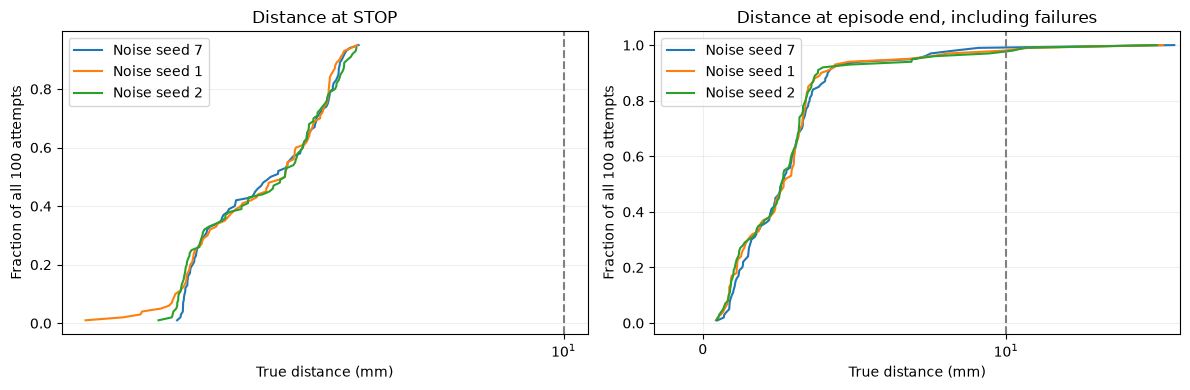

In [16]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for seed, audit in stack_audits.items():
    stop = np.sort([r['STOP_mm'] for r in audit['rows'] if r['STOP_mm'] is not None])
    final = np.sort([r['final_mm'] for r in audit['rows'] if r['final_mm'] is not None])
    axes[0].plot(stop, np.arange(1, len(stop)+1)/100, label=f'Noise seed {seed}')
    axes[1].plot(final, np.arange(1, len(final)+1)/100, label=f'Noise seed {seed}')
for ax, title in zip(axes, ['Distance at STOP', 'Distance at episode end, including failures']):
    ax.axvline(10, color='grey', ls='--'); ax.set(xlabel='True distance (mm)', ylabel='Fraction of all 100 attempts', title=title)
    ax.set_xscale('symlog', linthresh=10); ax.grid(alpha=.2); ax.legend()
fig.tight_layout(); fig.savefig(ROOT/'frozen_stack_distances.png', dpi=150); plt.show()


In [17]:
failure_rows = []
for seed, audit in stack_audits.items():
    for row in audit['failures']:
        failure_rows.append(dict(noise_seed=seed, target=row['dot'], status=row['status'], PARK=row['PARK'],
            park_s=row['park_s'], deadline_s=row['limit_s'], STOP_s=row['stop_s'],
            STOP_mm=row['STOP_mm'], final_mm=row['final_mm']))
display(pd.DataFrame(failure_rows).round(3))
print('Successful attempts with settling exceptions:', {s: [r['dot'] for r in a['settling_exceptions']] for s, a in stack_audits.items()})
print('Internal-motion diagnostic flags:', {s: [r['dot'] for r in a['internal_diagnostic_flags']] for s, a in stack_audits.items()})


,noise_seed,target,status,PARK,park_s,deadline_s,STOP_s,STOP_mm,final_mm
0,7,239,no_stop_timeout,True,4.767,12.000,None,None,41.330
1,7,479,no_stop_timeout,True,11.533,12.638,None,None,7.517
2,7,707,no_stop_timeout,True,10.733,12.669,None,None,7.328
3,7,738,no_stop_timeout,True,9.333,12.766,None,None,9.090
4,7,770,no_stop_timeout,True,9.700,12.273,None,None,8.274
5,1,239,no_stop_timeout,True,4.667,12.000,None,None,37.565
6,1,479,no_stop_timeout,True,11.600,12.638,None,None,7.544
7,1,707,no_stop_timeout,True,10.900,12.669,None,None,12.093
8,1,738,no_stop_timeout,True,9.367,12.766,None,None,9.904
9,1,770,no_stop_timeout,True,9.733,12.273,None,None,8.103


Successful attempts with settling exceptions: {7: [], 1: [], 2: []}
Internal-motion diagnostic flags: {7: [], 1: [], 2: []}


### Reading these results

The success counts, distance distributions and complete failure list above are loaded from the frozen evaluation records. Noise seeds reuse targets, so pooling them describes repeated trials rather than increasing the number of independent target locations. The clean and disturbed candidates also have different controller settings; this is a robustness extension, not an isolated measurement of the disturbances' causal effect.

Camera previews show the image captured at the displayed frame. With delay, the controller may use an earlier delivered image; capture and delivery timing are retained in the logs. The player displays final sent arm torque, including motor corrections, separately from the underlying requested torque. Requested torque clipping does not bound the final motor-corrected torque.

The unchanged coefficient-fitting curves appear earlier in this notebook. No additional neural training epochs or recovery-data training were performed for these three evaluations. Source, data and native executable hashes are preserved with the freeze and each evaluation.

The completed scores are 95/100, 95/100 and 94/100 for noise seeds 7, 1 and 2: 284 successful attempts out of 300. All 284 pass the settling check, with no post-STOP internal-motion audit flags. The ≥95-per-seed prediction misses by one attempt on seed 2. Median STOP distances are 4.882, 4.978 and 5.114 mm.

Five target IDs time out under every noise seed; target 545 additionally times out under seed 2. Target 239 repeatedly loses accepted camera updates near the end, leaving its arm target estimate more than nine seconds old. The other timeouts have fresh camera updates and limited time after PARK. Ten of the 16 timeouts finish within true 10 mm but never issue STOP; they remain failures. This is descriptive evidence, not a test-guided retuning proposal.

### Recorded disturbance replays

- [Disturbance stack, noise seed 7: 100 recorded test replays](https://nm-linmint-mlflow.taile381c0.ts.net:8443/golden-replays/directed-control-rnd/learned_geometry_branch/stack_recovery_reserved_recording_adapter_v1/test_seed7/viewer_test_seed7.html)
- [Disturbance stack, noise seed 1: 100 recorded test replays](https://nm-linmint-mlflow.taile381c0.ts.net:8443/golden-replays/directed-control-rnd/learned_geometry_branch/stack_reserved_seed1_v1/test_seed1/viewer_test_seed1.html)
- [Disturbance stack, noise seed 2: 100 recorded test replays](https://nm-linmint-mlflow.taile381c0.ts.net:8443/golden-replays/directed-control-rnd/learned_geometry_branch/stack_reserved_seed2_v1/test_seed2/viewer_test_seed2.html)

## Unpowered-wheel rowing probe

This separate, engineered demonstration is not imitation learning and is not a successful locomotion result. All four wheel actuator torques were explicitly zero, rather than commanding zero speed through a braking servo. The same course collision geometry and contact settings were retained; fingers kept their usual fixed-position commands.

Two short stroke attempts and matched stationary-arm controls ran on the Mac in PyBullet at 1 kHz. The second used lower damping on selected joints and a lower floor target; its control used identical gains. These are exploratory diagnostics, not reserved-target evaluations. The native Mint simulator was checked separately with a wheel-servo bypass and zero arm torque.

In [18]:
import json
import pandas as pd
from pathlib import Path
root = Path.cwd()
rowing_names = ['rowing_hold_probe1', 'rowing_stroke_probe1', 'rowing_hold_probe2', 'rowing_stroke_probe2']
rowing_rows = [dict(case=n, **json.loads((root/n/'summary.json').read_text())) for n in rowing_names]
pd.DataFrame(rowing_rows)[['case', 'forward_displacement_m', 'arm_floor_contact_seconds', 'wheel_sent_torque_max_Nm', 'wheel_actuator_work_J']]

,case,forward_displacement_m,arm_floor_contact_seconds,wheel_sent_torque_max_Nm,wheel_actuator_work_J
0,rowing_hold_probe1,-28.496120,0.000,0.0,0.0
1,rowing_stroke_probe1,-28.127435,0.019,0.0,0.0
2,rowing_hold_probe2,-27.468855,0.000,0.0,0.0
3,rowing_stroke_probe2,-20.176495,7.231,0.0,0.0


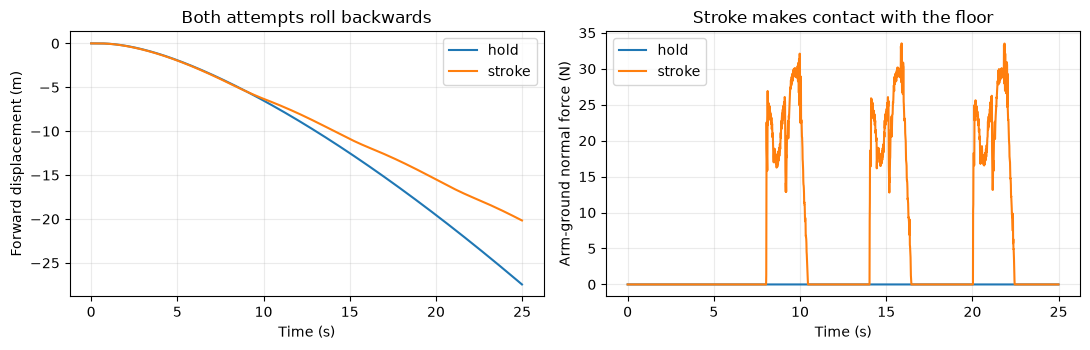

In [19]:
import numpy as np
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name in ['rowing_hold_probe2', 'rowing_stroke_probe2']:
    d = np.load(root/name/'trajectory_10ms.npz')['data']
    axes[0].plot(d[:,0], d[:,1]-d[0,1], label=name.replace('rowing_', '').replace('_probe2',''))
    axes[1].plot(d[:,0], d[:,-3], label=name.replace('rowing_', '').replace('_probe2',''))
axes[0].set(ylabel='Forward displacement (m)', xlabel='Time (s)', title='Both attempts roll backwards')
axes[1].set(ylabel='Arm-ground normal force (N)', xlabel='Time (s)', title='Stroke makes contact with the floor')
for ax in axes: ax.legend(); ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig('rowing_diagnostic.png', dpi=160)
plt.show()

The second stroke produced 7.231 seconds of arm-ground contact and zero wheel actuator work. It ended 20.18 m backwards; the matched control ended 27.47 m backwards. This is braking relative to an unexplained rolling control, not forward propulsion. The first stroke also failed. Both attempts and controls are retained.

The separate native zero-arm/zero-wheel check moved 1.247 m backwards in 5 seconds. It is not identical to the stationary-arm control because the arm can fall and the fingers retain position commands. The precise source of the large rolling motion remains unresolved; these observations do not establish an energy-conservation defect. No contact setting was changed to manufacture a successful demonstration.

[Recorded failed stroke](https://nm-linmint-mlflow.taile381c0.ts.net:8443/golden-replays/directed-control-rnd/rowing_stroke_probe2/recorded_probe.mp4)

### Analytical computation and the remaining simulation cost

The learned trigonometric position map already provides position and a Jacobian directly, without simulating a trajectory. An algebraically equivalent implementation was checked at 500 random joint configurations: maximum absolute difference below 1.5e-15. On the Mac, median evaluation fell from 654 to 279 microseconds for the seven-angle map, about 2.34 times faster. This is an inference-kernel measurement, not an end-to-end simulation speedup; frozen evaluated models were not changed.

It does not remove contact, motor dynamics or camera rendering from a faithful evaluation. A reduced dynamics model could be faster, but would require separate validation and would not replace the existing simulator evidence. Encoding a model or trajectory into one integer, including a Gödel-style encoding, does not by itself remove the work needed to decode it or compute the next physical state. No such shortcut was implemented or claimed.

## Published disturbance records

- [Disturbance noise seed 7: verified MLflow run](https://nm-linmint-mlflow.taile381c0.ts.net/#/experiments/4/runs/7211873c67b645f39c97282fa5f06c3d)
- [Disturbance noise seed 1: verified MLflow run](https://nm-linmint-mlflow.taile381c0.ts.net/#/experiments/4/runs/b8a50ca39aa743f7b916ce9b0d8c77e2)
- [Disturbance noise seed 2: verified MLflow run](https://nm-linmint-mlflow.taile381c0.ts.net/#/experiments/4/runs/924b1f04428142e68281028eb6d7e081)

All three runs contain frozen models, source archives, fitting records, full trajectory/camera recordings, alignment checks and the test metrics. Noise seeds are repeat measurements of one controller, not separately trained models.